# factorflow on a simulated market

This notebook drives factorflow end to end on **synthetic data with planted ground truth**
(`factorflow.sim`), so every number below can be checked against what the generator put in:

1. simulate a market: 100 equities on the XNYS calendar (incl. the 2026-11-27 early close) and BTC/ETH/SOL trading 24/7;
2. run a daily `Pipeline` in batch and look at the output;
3. stream the last session's ticks through `LiveEngine`, watch the open bar being revised, and check every sealed row against `BatchEngine` bit for bit;
4. validate against the truth: factor recovery, planted IC, a decile long-short backtest, and clock vs volume/dollar bar normality;
5. a quick performance run.

Run it with `uv run --group notebook jupyter nbconvert --execute --to notebook --inplace examples/demo.ipynb`
(or open it in Jupyter / VS Code with the `notebook` dependency group installed).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import factorflow as ff
from factorflow.grid import NS
from factorflow.sim import SimConfig, simulate
from factorflow.sim.pipelines import beta_window_for, daily_pipeline, minute_pipeline
from factorflow.sim.replay import Extras, ReplayStats, replay, verify_replay
from factorflow.sim.validate import validate

plt.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(12)

polars.config.Config

## 1. The simulated market

`SimConfig()` defaults: seed 7, 252 daily history sessions ending 2026-11-30, and full tick data for the
last 3 sessions. Daily log returns follow a planted factor model:

$r_{t,i} = \beta_i f^{mkt}_t + \sum_k x_{ik} f^k_t + g_{t,\mathrm{ind}(i)} + \kappa\,\sigma_{t,i}\, s_{t-1,i} + \sigma_{t,i}\,\varepsilon_{t,i}$

with GARCH(1,1) volatility and Student-t(5) shocks. The signal $s$ is AR(1) and z-scored each day, and
$\kappa = IC/\sqrt{1-IC^2}$, so its **risk-adjusted residual IC is the planted 0.03**. Intraday, prices follow a
Brownian bridge in *volume time* pinned to the daily close. Trades arrive as a Poisson process with a U-shaped
intraday profile and a persistent activity multiplier. Prices print with bid/ask bounce on a $0.01 tick. The
simulation also includes illiquid names with missing minute bars, trading halts, and overnight gaps.

In [2]:
t0 = time.perf_counter()
mkt = simulate(SimConfig())
print(f"simulated in {time.perf_counter() - t0:.1f} s")
print(mkt.summary())
eq, cr = mkt.equities, mkt.crypto

simulated in 1.0 s
equities   100 assets  255 daily bars (2025-11-24 .. 2026-11-30, calendar XNYS)  490,699 trades on 2026-11-25, 2026-11-27, 2026-11-30
          last close: median 65.56, range 9.28 .. 776.48;  halts: 4
crypto       3 assets  255 daily bars (2026-03-21 .. 2026-11-30, calendar 24/7)  73,664 trades on 2026-11-28, 2026-11-29, 2026-11-30
          last close: median 4,267.25, range 189.37 .. 106,799.89;  halts: 0
planted: 3 styles ('size', 'value', 'quality'), 8 industries, market beta ~ N(1.0, 0.3), signal IC 0.030 (kappa 0.0300), t(5.0) shocks


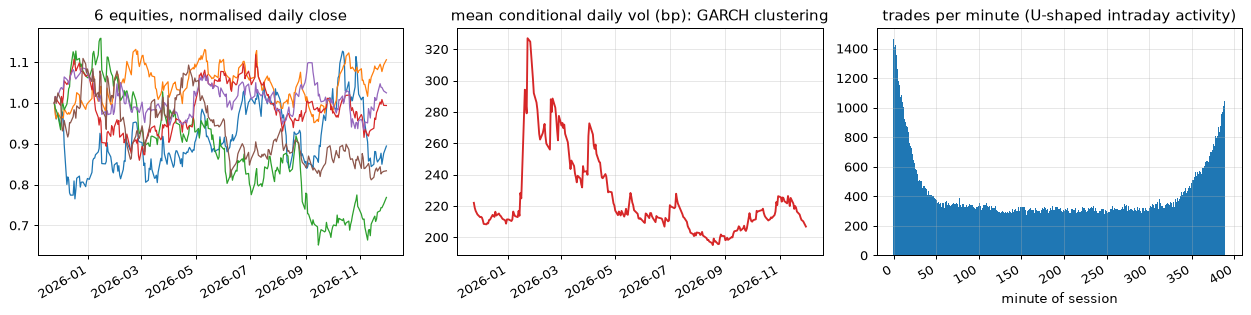

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
c = eq.daily.columns["close"]
days = eq.sessions.astype("datetime64[D]")
for j in range(6):
    ax[0].plot(days, c[:, j] / c[0, j], lw=1)
ax[0].set_title("6 equities, normalised daily close")
tr = eq.truth
ax[1].plot(days, 1e4 * tr.total_vol.mean(axis=1), color="C3")
ax[1].set_title("mean conditional daily vol (bp): GARCH clustering")
# intraday U-shape: trades per minute of the session, averaged over names and days
t = eq.trades
day = np.searchsorted(eq.closes, t.ts, side="left")
full = day[np.isin(day, eq.intraday[eq.closes[eq.intraday] - eq.opens[eq.intraday] == 390 * 60 * NS])]
m = np.isin(day, np.unique(full))
mins = (t.ts[m] - eq.opens[day[m]]) // (60 * NS)
ax[2].bar(np.arange(390), np.bincount(mins, minlength=390)[:390] / len(np.unique(full)), width=1.0)
ax[2].set_title("trades per minute (U-shaped intraday activity)")
ax[2].set_xlabel("minute of session")
fig.autofmt_xdate()
plt.tight_layout()

In [4]:
# crypto trades through the weekend; equities do not
for sim in (eq, cr):
    d = np.unique(sim.trades.ts.astype("datetime64[ns]").astype("datetime64[D]"))
    print(f"{sim.name:9s} {sim.calendar:5s} tick days:", ", ".join(f"{x} ({x.astype(object):%a})" for x in d))
print("halts:", [(eq.assets[a], np.datetime64(h0, "ns"), (h1 - h0) // (60 * NS)) for a, h0, h1 in eq.halts[:5]], "...")
ill = eq.daily.columns["n_ticks"][eq.intraday[-1]]
print("trades on the last session: min", int(ill.min()), "median", int(np.median(ill)), "max", int(ill.max()))

equities  XNYS  tick days: 2026-11-25 (Wed), 2026-11-27 (Fri), 2026-11-30 (Mon)
crypto    24/7  tick days: 2026-11-28 (Sat), 2026-11-29 (Sun), 2026-11-30 (Mon)
halts: [('EQ032', np.datetime64('2026-11-25T16:08:00.000000000'), 38), ('EQ088', np.datetime64('2026-11-25T19:36:00.000000000'), 37), ('EQ066', np.datetime64('2026-11-30T15:53:00.000000000'), 49), ('EQ086', np.datetime64('2026-11-30T16:14:00.000000000'), 57)] ...
trades on the last session: min 15 median 1082 max 10210


## 2. A daily Pipeline in batch

`daily_pipeline` (in `factorflow.sim.pipelines`) has:

- returns, demeaned market-relative returns, and a 200-day rolling beta against the equal-weight market;
- 20-day vol and momentum;
- industry-relative returns using the industry `Classifier`;
- the z-scored signal, with top and bottom decile `Filter`s masked by a universe screen;
- z-scored style exposures.

In [5]:
pipe = daily_pipeline(len(eq.assets), beta_window_for(eq.n_hist))
res = ff.BatchEngine().run(pipe, eq.daily)
res.frame().filter(pl.col("ts") == pl.col("ts").max()).sort("signal_z", descending=True).head(8)

ts,asset,is_open,ret,logret,mkt,…,signal_z,long,short,size_z,value_z,quality_z
"datetime[ns, UTC]",str,bool,f64,f64,f64,…,f64,bool,bool,f64,f64,f64
2026-11-30 21:00:00 UTC,"""EQ014""",false,0.004598,0.004588,-0.001656,…,2.565739,true,false,0.573705,0.820563,-0.908478
2026-11-30 21:00:00 UTC,"""EQ017""",false,0.000883,0.000882,-0.001656,…,2.293166,true,false,1.506612,-0.568049,0.147102
2026-11-30 21:00:00 UTC,"""EQ052""",false,0.001769,0.001768,-0.001656,…,2.26739,true,false,0.204164,0.346634,-0.689157
2026-11-30 21:00:00 UTC,"""EQ001""",false,0.011617,0.01155,-0.001656,…,1.972779,true,false,1.485373,0.326413,0.82664
2026-11-30 21:00:00 UTC,"""EQ021""",false,0.040217,0.039429,-0.001656,…,1.873808,true,false,0.04164,0.259529,-0.469751
2026-11-30 21:00:00 UTC,"""EQ095""",false,-0.003981,-0.003989,-0.001656,…,1.812689,true,false,-0.350022,0.145449,1.235962
2026-11-30 21:00:00 UTC,"""EQ002""",false,0.021336,0.021111,-0.001656,…,1.795566,true,false,-0.360226,-0.553785,1.405409
2026-11-30 21:00:00 UTC,"""EQ091""",false,-0.042312,-0.043233,-0.001656,…,1.53291,true,false,-0.640498,-0.397997,-0.542433


## 3. Live: ticks through `LiveEngine`

The engine is warmed on the first two intraday sessions of minute bars. We then stream the first 30 minutes
of the last session tick by tick, revising every second of market time and sealing on the 1-minute XNYS grid.
`replay(..., speed=60)` would pace this in accelerated real time. Here it runs flat out.

In [6]:
panel, _ = eq.time_bars("1min")
last_open = int(eq.opens[eq.intraday[-1]])
h = int(np.searchsorted(panel.times, last_open, side="right"))  # bars before the last session
live = ff.LiveEngine(minute_pipeline(), panel.head(h), ff.BarGrid("XNYS", "1min"))
extras = Extras(panel.times, {k: panel.columns[k] for k in ("signal", "industry")})
start = int(np.searchsorted(eq.trades.ts, last_open, side="left"))
stop = int(np.searchsorted(eq.trades.ts, last_open + 30 * 60 * NS, side="left"))
revisions = []
st = replay(live, eq.trades, start=start, stop=stop, extras=extras, revise_every_ns=NS,
            on_revise=revisions.append)
s = st.summary()
print(f"{int(s['ticks']):,} ticks, {s['revises']} revisions, {len(st.seal_ms)} sealed bars; "
      f"{s['ticks_per_s']:,.0f} ticks/s; revise p50 {s['revise_ms_p50']:.2f} ms, seal p50 {s['seal_ms_p50']:.2f} ms")
snap = revisions[-1]
print("open bar ends", np.datetime64(snap.ts, "ns"), "UTC; is_open =", snap.is_open)
snap.frame().sort("score", descending=True, nulls_last=True).head(8)

24,855 ticks, 1800 revisions, 29 sealed bars; 18,726 ticks/s; revise p50 0.63 ms, seal p50 0.23 ms
open bar ends 2026-11-30T15:00:00.000000000 UTC; is_open = True


ts,asset,is_open,close,ret1,mom30,…,rel_vol,range30,ewm_ret,score,rank,long
"datetime[ns, UTC]",str,bool,f64,f64,f64,…,f64,f64,f64,f64,f64,f64
2026-11-30 15:00:00 UTC,"""EQ014""",true,65.1,0.0,-0.002146,…,0.144687,0.005837,0.000051,3.349635,1.0,1.0
2026-11-30 15:00:00 UTC,"""EQ052""",true,39.8,-0.001004,0.006067,…,0.275098,0.011055,-0.000078,2.996487,2.0,1.0
2026-11-30 15:00:00 UTC,"""EQ095""",true,47.63,0.001051,-0.002095,…,1.315367,0.006718,0.000031,2.445754,3.0,1.0
2026-11-30 15:00:00 UTC,"""EQ055""",true,40.93,0.000244,-0.001951,…,0.2403,0.003909,0.000046,2.354806,4.0,1.0
2026-11-30 15:00:00 UTC,"""EQ085""",true,143.47,0.001116,0.014137,…,0.360315,0.008504,0.000168,2.334327,5.0,1.0
2026-11-30 15:00:00 UTC,"""EQ021""",true,31.34,0.000319,0.000319,…,0.314286,0.008296,0.000142,2.333109,6.0,1.0
2026-11-30 15:00:00 UTC,"""EQ022""",true,783.96,-0.000026,0.000996,…,0.209325,0.00722,0.000247,2.330322,7.0,1.0
2026-11-30 15:00:00 UTC,"""EQ075""",true,134.4,-0.000521,-0.000966,…,2.946083,0.006101,-0.000205,2.061666,8.0,1.0


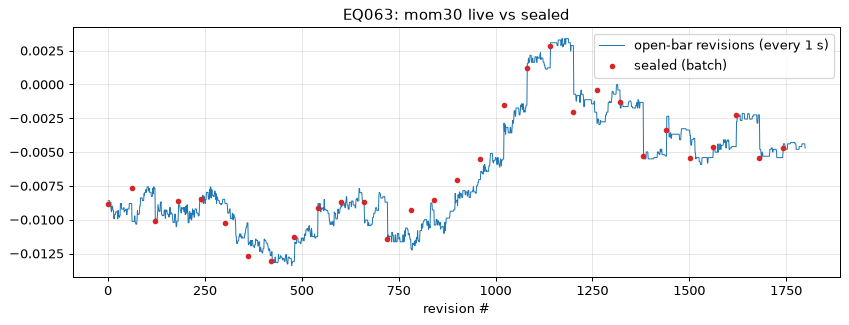

In [7]:
# how one name's provisional 30-minute momentum evolves inside the open bars, vs the sealed values
j = int(np.nanargmax(eq.daily.columns["n_ticks"][eq.intraday[-1]]))
ts = np.array([r.ts for r in revisions])
x = np.array([r.values["mom30"][j] for r in revisions])
sealed = ff.BatchEngine().run(minute_pipeline(), panel)
k = np.searchsorted(panel.times, ts.min()), np.searchsorted(panel.times, ts.max()) + 1
plt.plot(np.arange(len(x)), x, lw=0.8, label="open-bar revisions (every 1 s)")
pos = np.searchsorted(ts, panel.times[k[0]:k[1]]) - 1  # last revision of each bar
plt.scatter(pos, sealed.values["mom30"][k[0]:k[1], j], color="C3", s=12, zorder=3, label="sealed (batch)")
plt.title(f"{eq.assets[j]}: mom30 live vs sealed"); plt.legend(); plt.xlabel("revision #");

### Live vs batch, bit for bit

`verify_replay` replays **every** tick and compares each sealed live row with `BatchEngine` on the same bars,
using exact float equality. It also rebuilds sampled open revisions as batch rows. The check covers daily bars
revised by ticks, the 1-minute XNYS grid through the 13:00 ET early close on 2026-11-27, and 24/7 crypto.

In [8]:
checks = [
    ("equity daily", daily_pipeline(len(eq.assets), beta_window_for(eq.n_hist)), eq.daily, eq, eq.daily_grid(),
     eq.n_hist, ("signal", "industry", "size", "value", "quality"), 60 * NS),
    ("equity 1min", minute_pipeline(), panel, eq, ff.BarGrid("XNYS", "1min"),
     int(np.searchsorted(panel.times, eq.closes[eq.intraday[0]], side="right")), ("signal", "industry"), NS),
]
for label, p, full, sim, grid, hist, extra, every in checks:
    t0 = time.perf_counter()
    v = verify_replay(p, full, sim.trades, grid, hist, extra_columns=extra, revise_every_ns=every, check_open_every=200)
    print(f"{label:13s} ok={v.ok}  sealed rows {v.sealed_rows}, open revisions rebuilt {v.open_checked}, "
          f"mismatches {len(v.mismatches)}  ({time.perf_counter() - t0:.1f} s)")

equity daily  ok=True  sealed rows 3, open revisions rebuilt 4, mismatches 0  (2.6 s)


equity 1min   ok=True  sealed rows 600, open revisions rebuilt 179, mismatches 0  (34.4 s)


## 4. Validation against the planted truth

In [9]:
t0 = time.perf_counter()
val = validate(mkt)
print(val.report())
print(f"({time.perf_counter() - t0:.1f} s)")

Factor recovery (daily cross-sectional OLS on true exposures):
  factor      corr  slope  bias bp true vol bp err vol bp
  market     0.907  1.013    -0.81       133.6       62.9
  size       0.889  0.995    -0.76        42.3       21.6
  value      0.834  0.961     2.02        31.2       19.9
  quality    0.811  0.971     0.55        24.5       17.1
  ind0       0.611  0.937     0.69        67.7       82.4
  industries (8): mean corr 0.676, mean slope 0.965
  rolling beta vs true beta (100 names): corr 0.907, slope 0.951, MAE 0.096
Planted signal:
  risk-adjusted residual IC 0.0331 ± 0.0065 (planted 0.0300, z = +0.48) over 235 days;  raw IC 0.0277, rank IC 0.0315
  decile long-short (10 long / 10 short): mean 20.2 bp/day (expected ~16.4), vol 87 bp, Sharpe 3.70, t 3.57, hit 60.9%
Equity intraday return distributions (pooled, standardised per asset):
  bars           n bars/day   skew  ex.kurt med kurt         JB
  1min       93765    329.0  -0.00     3.69     2.89      53133
  5min   

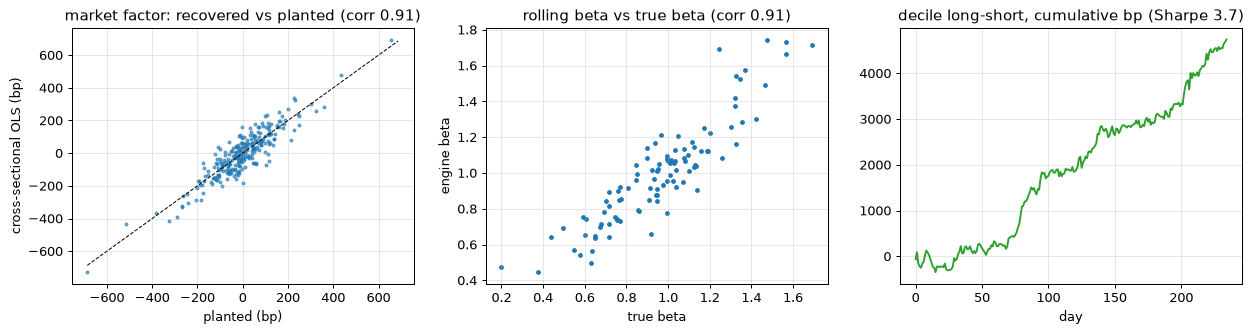

In [10]:
rec, bt = val.recovery, val.backtest
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ft = tr.factor_returns["market"][1:]
fh = rec.factor_hat["market"][1:]
ax[0].scatter(1e4 * ft, 1e4 * fh, s=5, alpha=0.6)
lim = 1e4 * np.nanmax(np.abs(ft))
ax[0].plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax[0].set(title=f"market factor: recovered vs planted (corr {rec.factors['market']['corr']:.2f})",
          xlabel="planted (bp)", ylabel="cross-sectional OLS (bp)")
bh = res.values["beta"][-1]
ax[1].scatter(tr.beta, bh, s=8)
ax[1].set(title=f"rolling beta vs true beta (corr {rec.beta['corr']:.2f})", xlabel="true beta", ylabel="engine beta")
ax[2].plot(np.cumsum(bt.daily) * 1e4, color="C2")
ax[2].set(title=f"decile long-short, cumulative bp (Sharpe {bt.sharpe:.1f})", xlabel="day")
plt.tight_layout()

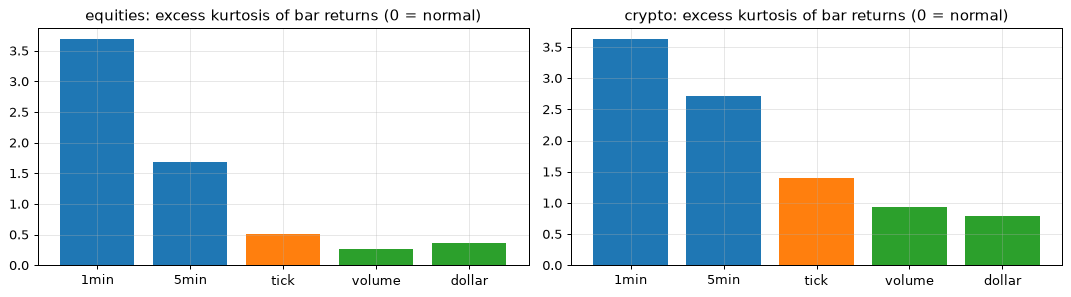

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, (title, d) in zip(ax, (("equities", val.bars), ("crypto", val.crypto_bars)), strict=True):
    names = list(d)
    a.bar(names, [d[k]["exkurt"] for k in names], color=["C0", "C0", "C1", "C2", "C2"])
    a.set(title=f"{title}: excess kurtosis of bar returns (0 = normal)")
plt.tight_layout()

Event bars sample in volume or dollar time, the clock the generator's price process runs on. Their returns are
close to normal (excess kurtosis about 0.3 vs 3.7 for 1-minute bars, with JB an order of magnitude lower),
which is the Clark / López de Prado result. The beta, factor and IC recoveries sit within sampling error of the
planted values.

## 5. Performance

A short run of `factorflow.sim.bench` covers ticks per second and revise/seal latency on the minute pipeline.
The full table at 100 and 500 names is in the README (`python -m factorflow.sim bench`).

In [12]:
from factorflow.sim.bench import format_bench, run_bench

rows = run_bench(names=(100,), minutes=5, pipelines=("demo",))
print(format_bench(rows, 5))

factorflow replay benchmark: XNYS 1-minute grid, first 5 min of a session (revise@tick: first 5 min)
python 3.13.5  numpy 2.5.4  x86_64  cpus=8
  names pipeline nodes mode           ticks   ticks/s x realtime tick us  revise p50/p95 ms  seal p50/p95 ms
    100 demo        36 ingest          6962   455,604     19,624    1.24                  - 0.66/0.84
    100 demo        36 revise@1s       6962    35,554      1,531    1.42          0.59/0.73 0.23/0.24
    100 demo        36 revise@tick     6962     1,700         73    3.79          0.58/0.88 0.25/0.26
